# L4. Uninformed Search Strategies 

Solving Problems by Searching is not just a fundamental concept in the field of AI. This approach is widely used in various domains such as robotics, game playing, pathfinding, and automated planning.

In this assignment, we will design a maze generator that creates a unique maze on each run, along with an agent that finds its way from the starting state to the target state using uninformed search strategies.

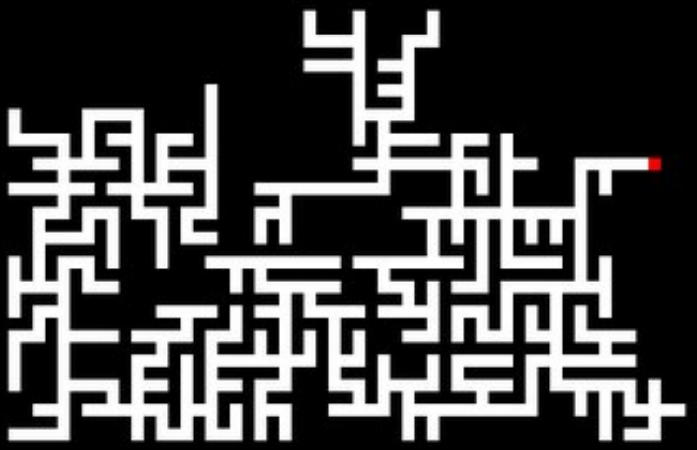

## Maze & State Space

Mazes are a classic example of a state-space search problem in AI. 

* **State**: Each position in the maze (e.g., a specific grid cell) represents a state.
* **Actions**: The ***possible*** moves an agent can make from a given state, such as moving *up, down, left*, or *right*.
* **Goal**: The state where the agent needs to arrive, such as the maze's exit or the cell with a treasure.

Besides maze games, maze generation has all sorts of applications, including but not limited to:
* Creating terrain with obstacles
* Creating the layout of rooms in a dungeon crawler
* Generating puzzles
* Generating cool visuals
* Teaching graph algorithms 
       

### Maze generator

To generate a maze, you can use algorithms (there are MANY maze generation algorithms)
* Depth First Search

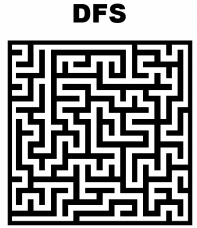

* Prim’s Algorithm

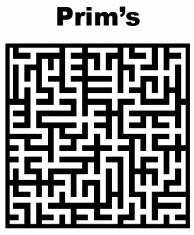

* Kruskal’s Algorithm (Kruskal looks the same as Prim’s)

* Eller’s Algorithm (extremely high complexity)

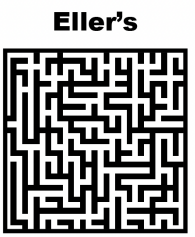

OR you can develop your own simple Maze generator (as we are going to do).

The `maze` can be represented as a `2D array`, where:
* **0** represents a **wall** , 
* and **1** represents an **open path**.

In [ ]:
n=4

In [ ]:
from src.mazeData import makeMaze

In [ ]:
maze1=makeMaze(n)
maze1

array([[1, 1, 1, 0],
       [1, 1, 1, 1],
       [1, 1, 1, 0],
       [1, 1, 0, 1]])

Now we nee to define actions.

If define possible actions based on the locaion of the cell, like the following one:

In [ ]:
from src.mazeData import defineMazeActions

In [ ]:
mazeALLActs=defineMazeActions(maze1)
mazeALLActs

{(0, 0): ['right', 'down'],
 (0, 1): ['left', 'right', 'down'],
 (0, 2): ['left', 'right', 'down'],
 (0, 3): ['left', 'down'],
 (1, 0): ['up', 'right', 'down'],
 (1, 1): ['left', 'up', 'right', 'down'],
 (1, 2): ['left', 'up', 'right', 'down'],
 (1, 3): ['left', 'up', 'down'],
 (2, 0): ['up', 'right', 'down'],
 (2, 1): ['left', 'up', 'right', 'down'],
 (2, 2): ['left', 'up', 'right', 'down'],
 (2, 3): ['left', 'up', 'down'],
 (3, 0): ['up', 'right'],
 (3, 1): ['left', 'up', 'right'],
 (3, 2): ['left', 'up', 'right'],
 (3, 3): []}

!!! BUT This means that all cells in any possible maze will have the same set of actins regardless the structure of the maze.

In [ ]:
from src.mazeData import defineMazeAvailableActions

In [ ]:
mazeAvalActs=defineMazeAvailableActions(maze1)
mazeAvalActs

{(0, 0): ['right', 'down'],
 (0, 1): ['left', 'right', 'down'],
 (0, 2): ['left', 'down'],
 (0, 3): [],
 (1, 0): ['up', 'right', 'down'],
 (1, 1): ['left', 'up', 'right', 'down'],
 (1, 2): ['left', 'up', 'right', 'down'],
 (1, 3): ['left'],
 (2, 0): ['up', 'right', 'down'],
 (2, 1): ['left', 'up', 'right', 'down'],
 (2, 2): ['left', 'up'],
 (2, 3): [],
 (3, 0): ['up', 'right'],
 (3, 1): ['left', 'up'],
 (3, 2): [],
 (3, 3): []}

In [ ]:
maze1

array([[1, 1, 1, 0],
       [1, 1, 1, 1],
       [1, 1, 1, 0],
       [1, 1, 0, 1]])

Next we need to define the **Transition (Transformation) Model (TM)**

Transition Model: Describes what each action does. RESULT(s, a) returns the state that results from performing action "a" in state "s".

In [ ]:
from src.mazeData import makeMazeTransformationModel

Since the TM describes what each action does the set of available actions is used as a input for it.

In [ ]:
maze1TM=makeMazeTransformationModel(mazeAvalActs)
maze1TM

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1), 'down': (1, 2)},
 (0, 3): {},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'right': (1, 2), 'down': (2, 1)},
 (1, 2): {'left': (1, 1), 'up': (0, 2), 'right': (1, 3), 'down': (2, 2)},
 (1, 3): {'left': (1, 2)},
 (2, 0): {'up': (1, 0), 'right': (2, 1), 'down': (3, 0)},
 (2, 1): {'left': (2, 0), 'up': (1, 1), 'right': (2, 2), 'down': (3, 1)},
 (2, 2): {'left': (2, 1), 'up': (1, 2)},
 (2, 3): {},
 (3, 0): {'up': (2, 0), 'right': (3, 1)},
 (3, 1): {'left': (3, 0), 'up': (2, 1)},
 (3, 2): {},
 (3, 3): {}}

The data above is our graph data to build the `MazeGraph`

### Maze Graph

In [ ]:
from src.graphProblemClass import GraphProblem

Based on this dictionary we need to build a graph
* !!! Check the `Graph class`

However, we need to create the derived class - `mazeGraph`

In [ ]:
from src.maze2026GraphClass import mazeGraph

In [ ]:
from src.mazeData import mazeStatesLocations

In [ ]:
list(maze1TM.keys())

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (2, 0),
 (2, 1),
 (2, 2),
 (2, 3),
 (3, 0),
 (3, 1),
 (3, 2),
 (3, 3)]

In [ ]:
mazeWorldGraph = mazeGraph(maze1TM, mazeStatesLocations(list(maze1TM.keys())))

In [ ]:
mazeWorldGraph.nodes()

[(0, 1),
 (1, 2),
 (2, 1),
 (0, 0),
 (3, 1),
 (1, 1),
 (2, 0),
 (3, 0),
 (0, 2),
 (2, 2),
 (1, 0),
 (1, 3)]

In [ ]:
mazeWorldGraph.graph_dict

{(0, 0): {(0, 1): 1, (1, 0): 1},
 (0, 1): {(0, 0): 1, (0, 2): 1, (1, 1): 1},
 (0, 2): {(0, 1): 1, (1, 2): 1},
 (1, 0): {(0, 0): 1, (1, 1): 1, (2, 0): 1},
 (1, 1): {(1, 0): 1, (0, 1): 1, (1, 2): 1, (2, 1): 1},
 (1, 2): {(1, 1): 1, (0, 2): 1, (1, 3): 1, (2, 2): 1},
 (1, 3): {(1, 2): 1},
 (2, 0): {(1, 0): 1, (2, 1): 1, (3, 0): 1},
 (2, 1): {(2, 0): 1, (1, 1): 1, (2, 2): 1, (3, 1): 1},
 (2, 2): {(2, 1): 1, (1, 2): 1},
 (3, 0): {(2, 0): 1, (3, 1): 1},
 (3, 1): {(3, 0): 1, (2, 1): 1}}

In [ ]:
mazeWorldGraph.origin

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1), 'down': (1, 2)},
 (0, 3): {},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'right': (1, 2), 'down': (2, 1)},
 (1, 2): {'left': (1, 1), 'up': (0, 2), 'right': (1, 3), 'down': (2, 2)},
 (1, 3): {'left': (1, 2)},
 (2, 0): {'up': (1, 0), 'right': (2, 1), 'down': (3, 0)},
 (2, 1): {'left': (2, 0), 'up': (1, 1), 'right': (2, 2), 'down': (3, 1)},
 (2, 2): {'left': (2, 1), 'up': (1, 2)},
 (2, 3): {},
 (3, 0): {'up': (2, 0), 'right': (3, 1)},
 (3, 1): {'left': (3, 0), 'up': (2, 1)},
 (3, 2): {},
 (3, 3): {}}

In [ ]:
mazeWorldGraph.locations

{(0, 0): (0, 0),
 (0, 1): (50, 0),
 (0, 2): (100, 0),
 (0, 3): (150, 0),
 (1, 0): (0, 50),
 (1, 1): (50, 50),
 (1, 2): (100, 50),
 (1, 3): (150, 50),
 (2, 0): (0, 100),
 (2, 1): (50, 100),
 (2, 2): (100, 100),
 (2, 3): (150, 100),
 (3, 0): (0, 150),
 (3, 1): (50, 150),
 (3, 2): (100, 150),
 (3, 3): (150, 150)}

In [ ]:
mazeWorldGraph.get((0, 1), (0,2))

1

#### Visualization of Net_Maze

Let's try to show the graph of our Maze

In [ ]:
from pyvis.network import Network 

In [ ]:
net_maze = Network( heading="Lab4. Examples of Maze World Problem",
                bgcolor ="#242020",
                font_color = "white",
                height = "750px",
                width = "100%" 
) # do this


In [ ]:
mazeWorldGraph.origin

{(0, 0): {},
 (0, 1): {'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1), 'right': (0, 3), 'down': (1, 2)},
 (0, 3): {'left': (0, 2), 'down': (1, 3)},
 (1, 0): {},
 (1, 1): {'up': (0, 1), 'right': (1, 2), 'down': (2, 1)},
 (1, 2): {'left': (1, 1), 'up': (0, 2), 'right': (1, 3), 'down': (2, 2)},
 (1, 3): {'left': (1, 2), 'up': (0, 3), 'down': (2, 3)},
 (2, 0): {'right': (2, 1), 'down': (3, 0)},
 (2, 1): {'left': (2, 0), 'up': (1, 1), 'right': (2, 2), 'down': (3, 1)},
 (2, 2): {'left': (2, 1), 'up': (1, 2), 'right': (2, 3), 'down': (3, 2)},
 (2, 3): {'left': (2, 2), 'up': (1, 3)},
 (3, 0): {'up': (2, 0), 'right': (3, 1)},
 (3, 1): {'left': (3, 0), 'up': (2, 1), 'right': (3, 2)},
 (3, 2): {'left': (3, 1), 'up': (2, 2)},
 (3, 3): {}}

In [ ]:
maze1

array([[1, 1, 1, 0],
       [1, 1, 1, 1],
       [1, 1, 1, 0],
       [1, 1, 0, 1]])

In [ ]:
maze1[0,1]

np.int64(1)

In [ ]:
nodeColors={
    "wall":"red",
    "path": "white"
}

In [ ]:
nodeColorsList=[]

for node in mazeWorldGraph.origin.keys():
    if maze1[node[0],node[1]]==1:
        nodeColorsList.append(nodeColors["path"])
    else:
        nodeColorsList.append(nodeColors["wall"])
nodeColorsList

['white',
 'white',
 'white',
 'red',
 'white',
 'white',
 'white',
 'white',
 'white',
 'white',
 'white',
 'red',
 'white',
 'white',
 'red',
 'white']

In [ ]:
nodes=["-".join(str(item) for item in el) for el in mazeWorldGraph.origin.keys()]
nodes

['0-0',
 '0-1',
 '0-2',
 '0-3',
 '1-0',
 '1-1',
 '1-2',
 '1-3',
 '2-0',
 '2-1',
 '2-2',
 '2-3',
 '3-0',
 '3-1',
 '3-2',
 '3-3']

In [ ]:
x_coords = []
y_coords = []

for node in mazeWorldGraph.origin.keys():
    x,y=mazeWorldGraph.getLocation(node)
    x_coords.append(x)
    y_coords.append(y)

print(x_coords)   
print(y_coords)


[0, 50, 100, 150, 0, 50, 100, 150, 0, 50, 100, 150, 0, 50, 100, 150]
[0, 0, 0, 0, 50, 50, 50, 50, 100, 100, 100, 100, 150, 150, 150, 150]


In [ ]:
sizes=[10]*len(nodes)
sizes

[10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]

In [ ]:
#hidden labels, and hover titles
net_maze.add_nodes(nodes, color=nodeColorsList, x=x_coords, y=y_coords, size=sizes, title=nodes)

In [ ]:
for node in net_maze.nodes:
    node['label']=''

In [ ]:
net_maze.nodes

[{'color': 'white',
  'x': 0,
  'y': 0,
  'size': 10,
  'title': '0-0',
  'id': '0-0',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 50,
  'y': 0,
  'size': 10,
  'title': '0-1',
  'id': '0-1',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 100,
  'y': 0,
  'size': 10,
  'title': '0-2',
  'id': '0-2',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'red',
  'x': 150,
  'y': 0,
  'size': 10,
  'title': '0-3',
  'id': '0-3',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 0,
  'y': 50,
  'size': 10,
  'title': '1-0',
  'id': '1-0',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 50,
  'y': 50,
  'size': 10,
  'title': '1-1',
  'id': '1-1',
  'label': '',
  'shape': 'dot',
  'font': {'color': 'white'}},
 {'color': 'white',
  'x': 100,
  'y': 50,
  'size': 10,
  'title': '1-2',
  'id': '1-2'

In [ ]:
mazeWorldGraph.origin[(1,1)]

{'up': (0, 1), 'right': (1, 2), 'down': (2, 1)}

In [ ]:
from src.mazeData import intTupleTostr

In [ ]:
intTupleTostr((0,0))

'0-0'

In [ ]:
edge_weights = {(intTupleTostr(k), intTupleTostr(v2)) : k2 for k, v in mazeWorldGraph.origin.items() for k2, v2 in v.items()}#actions
edge_weights

{('0-0', '0-1'): 'right',
 ('0-0', '1-0'): 'down',
 ('0-1', '0-0'): 'left',
 ('0-1', '0-2'): 'right',
 ('0-1', '1-1'): 'down',
 ('0-2', '0-1'): 'left',
 ('0-2', '1-2'): 'down',
 ('1-0', '0-0'): 'up',
 ('1-0', '1-1'): 'right',
 ('1-0', '2-0'): 'down',
 ('1-1', '1-0'): 'left',
 ('1-1', '0-1'): 'up',
 ('1-1', '1-2'): 'right',
 ('1-1', '2-1'): 'down',
 ('1-2', '1-1'): 'left',
 ('1-2', '0-2'): 'up',
 ('1-2', '1-3'): 'right',
 ('1-2', '2-2'): 'down',
 ('1-3', '1-2'): 'left',
 ('2-0', '1-0'): 'up',
 ('2-0', '2-1'): 'right',
 ('2-0', '3-0'): 'down',
 ('2-1', '2-0'): 'left',
 ('2-1', '1-1'): 'up',
 ('2-1', '2-2'): 'right',
 ('2-1', '3-1'): 'down',
 ('2-2', '2-1'): 'left',
 ('2-2', '1-2'): 'up',
 ('3-0', '2-0'): 'up',
 ('3-0', '3-1'): 'right',
 ('3-1', '3-0'): 'left',
 ('3-1', '2-1'): 'up'}

In [ ]:
mazeWorldGraph.nodes()

[(0, 1),
 (1, 2),
 (2, 1),
 (0, 0),
 (3, 1),
 (1, 1),
 (2, 0),
 (3, 0),
 (0, 2),
 (2, 2),
 (1, 0),
 (1, 3)]

In [ ]:
edges=[]

for node_source in mazeWorldGraph.nodes():
    for node_target, action in mazeWorldGraph.get(node_source).items():
        #node_target or node_source is a tuple -> convert to str
        if (intTupleTostr(node_source),intTupleTostr(node_target)) not in edges and (intTupleTostr(node_target), intTupleTostr(node_source)):
            net_maze.add_edge(intTupleTostr(node_source),intTupleTostr(node_target), label=edge_weights[(intTupleTostr(node_source),intTupleTostr(node_target))])
            edges.append((intTupleTostr(node_source),intTupleTostr(node_target)))
            



In [ ]:
# Disable physics
net_maze.toggle_physics(False)
net_maze.show("graph1.html", notebook=False)

graph1.html


In [ ]:
maze1

array([[0, 1, 1, 1],
       [0, 1, 1, 1],
       [1, 1, 1, 1],
       [1, 1, 1, 0]])

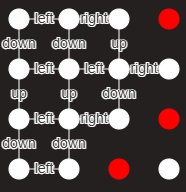

### Maze Problem formulation

Explore the derived *class MazeProblem(Problem)* for our Maze World example

In [ ]:
from src.mazeProblemClass import MazeProblem

In [ ]:
initState, goalState=(1,1),(2,2)

In [ ]:
mp1=MazeProblem(initState,goalState,mazeWorldGraph)

In [ ]:
mazeWorldGraph.graph_dict

{(0, 0): {(0, 1): 1, (1, 0): 1},
 (0, 1): {(0, 0): 1, (0, 2): 1, (1, 1): 1},
 (0, 2): {(0, 1): 1, (1, 2): 1},
 (1, 0): {(0, 0): 1, (1, 1): 1, (2, 0): 1},
 (1, 1): {(1, 0): 1, (0, 1): 1, (1, 2): 1, (2, 1): 1},
 (1, 2): {(1, 1): 1, (0, 2): 1, (1, 3): 1, (2, 2): 1},
 (1, 3): {(1, 2): 1},
 (2, 0): {(1, 0): 1, (2, 1): 1, (3, 0): 1},
 (2, 1): {(2, 0): 1, (1, 1): 1, (2, 2): 1, (3, 1): 1},
 (2, 2): {(2, 1): 1, (1, 2): 1},
 (3, 0): {(2, 0): 1, (3, 1): 1},
 (3, 1): {(3, 0): 1, (2, 1): 1}}

In [ ]:
mazeWorldGraph.origin

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1), 'down': (1, 2)},
 (0, 3): {},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'right': (1, 2), 'down': (2, 1)},
 (1, 2): {'left': (1, 1), 'up': (0, 2), 'right': (1, 3), 'down': (2, 2)},
 (1, 3): {'left': (1, 2)},
 (2, 0): {'up': (1, 0), 'right': (2, 1), 'down': (3, 0)},
 (2, 1): {'left': (2, 0), 'up': (1, 1), 'right': (2, 2), 'down': (3, 1)},
 (2, 2): {'left': (2, 1), 'up': (1, 2)},
 (2, 3): {},
 (3, 0): {'up': (2, 0), 'right': (3, 1)},
 (3, 1): {'left': (3, 0), 'up': (2, 1)},
 (3, 2): {},
 (3, 3): {}}

In [ ]:
mp1.graph.graph_dict.get(a).get(b)

1

In [ ]:
mp1.graph.origin[(0, 1)]['right']

(0, 2)

In [ ]:
mp1.result((0, 1), 'right')

1


(0, 2)

In [ ]:
a=(1, 1);b=(2,1)

In [ ]:
testState=(1,1)

In [ ]:
mp1.actions(testState)

['left', 'up', 'right', 'down']

## Problem Solving Agent in Maze

Now we are ready to consider `MazeProblemSolvingAgent class`

Explore the derived class `VacuumProblem(Problem)` for our Vacuum World example

However, we also need to check how our `BestFirstSearchAgentProgram` is able to process Maze World

In [ ]:
from src.PS_agentPrograms import BestFirstSearchAgentProgram

In [ ]:
BFSAP1=BestFirstSearchAgentProgram()

In [ ]:
mp1.initial #mp1 instance of Maze Problem

(1, 1)

In [ ]:
seq=BFSAP1(mp1)

<Node (1, 1)>
1
next_state (1, 0)
(1, 1) (1, 0)
1
1
next_state (0, 1)
(1, 1) (0, 1)
1
1
next_state (1, 2)
(1, 1) (1, 2)
1
1
next_state (2, 1)
(1, 1) (2, 1)
1
<Node (0, 1)>
1
next_state (0, 0)
(0, 1) (0, 0)
1
1
next_state (0, 2)
(0, 1) (0, 2)
1
1
next_state (1, 1)
(0, 1) (1, 1)
1
<Node (0, 0)>
1
next_state (0, 1)
(0, 0) (0, 1)
1
1
next_state (1, 0)
(0, 0) (1, 0)
1
<Node (0, 2)>
1
next_state (0, 1)
(0, 2) (0, 1)
1
1
next_state (1, 2)
(0, 2) (1, 2)
1
<Node (1, 0)>
1
next_state (0, 0)
(1, 0) (0, 0)
1
1
next_state (1, 1)
(1, 0) (1, 1)
1
1
next_state (2, 0)
(1, 0) (2, 0)
1
<Node (1, 2)>
1
next_state (1, 1)
(1, 2) (1, 1)
1
1
next_state (0, 2)
(1, 2) (0, 2)
1
1
next_state (1, 3)
(1, 2) (1, 3)
1
1
next_state (2, 2)
(1, 2) (2, 2)
1
<Node (1, 3)>
1
next_state (1, 2)
(1, 3) (1, 2)
1
<Node (2, 0)>
1
next_state (1, 0)
(2, 0) (1, 0)
1
1
next_state (2, 1)
(2, 0) (2, 1)
1
1
next_state (3, 0)
(2, 0) (3, 0)
1
<Node (2, 1)>
1
next_state (2, 0)
(2, 1) (2, 0)
1
1
next_state (1, 1)
(2, 1) (1, 1)
1
1
next_sta

In [ ]:
seq

<Node (2, 2)>

In [ ]:
from src.agents import ProblemSolvingMazeAgentBFS

In [ ]:
BFS_MazeAgent1=ProblemSolvingMazeAgentBFS(initState,mazeWorldGraph,goalState)

In [ ]:
BFS_MazeAgent1.goal

(2, 2)

In [ ]:
mazeWorldGraph.origin

{(0, 0): {'right': (0, 1), 'down': (1, 0)},
 (0, 1): {'left': (0, 0), 'right': (0, 2), 'down': (1, 1)},
 (0, 2): {'left': (0, 1), 'down': (1, 2)},
 (0, 3): {},
 (1, 0): {'up': (0, 0), 'right': (1, 1), 'down': (2, 0)},
 (1, 1): {'left': (1, 0), 'up': (0, 1), 'right': (1, 2), 'down': (2, 1)},
 (1, 2): {'left': (1, 1), 'up': (0, 2), 'right': (1, 3), 'down': (2, 2)},
 (1, 3): {'left': (1, 2)},
 (2, 0): {'up': (1, 0), 'right': (2, 1), 'down': (3, 0)},
 (2, 1): {'left': (2, 0), 'up': (1, 1), 'right': (2, 2), 'down': (3, 1)},
 (2, 2): {'left': (2, 1), 'up': (1, 2)},
 (2, 3): {},
 (3, 0): {'up': (2, 0), 'right': (3, 1)},
 (3, 1): {'left': (3, 0), 'up': (2, 1)},
 (3, 2): {},
 (3, 3): {}}

In [ ]:
testNode=(0,2)

In [ ]:
BFS_MazeAgent1(testNode)

<Node (0, 2)>
1
next_state (0, 1)
(0, 2) (0, 1)
1
1
next_state (1, 2)
(0, 2) (1, 2)
1
<Node (0, 1)>
1
next_state (0, 0)
(0, 1) (0, 0)
1
1
next_state (0, 2)
(0, 1) (0, 2)
1
1
next_state (1, 1)
(0, 1) (1, 1)
1
<Node (0, 0)>
1
next_state (0, 1)
(0, 0) (0, 1)
1
1
next_state (1, 0)
(0, 0) (1, 0)
1
<Node (1, 0)>
1
next_state (0, 0)
(1, 0) (0, 0)
1
1
next_state (1, 1)
(1, 0) (1, 1)
1
1
next_state (2, 0)
(1, 0) (2, 0)
1
<Node (1, 1)>
1
next_state (1, 0)
(1, 1) (1, 0)
1
1
next_state (0, 1)
(1, 1) (0, 1)
1
1
next_state (1, 2)
(1, 1) (1, 2)
1
1
next_state (2, 1)
(1, 1) (2, 1)
1
<Node (1, 2)>
1
next_state (1, 1)
(1, 2) (1, 1)
1
1
next_state (0, 2)
(1, 2) (0, 2)
1
1
next_state (1, 3)
(1, 2) (1, 3)
1
1
next_state (2, 2)
(1, 2) (2, 2)
1
<Node (1, 3)>
1
next_state (1, 2)
(1, 3) (1, 2)
1
<Node (2, 0)>
1
next_state (1, 0)
(2, 0) (1, 0)
1
1
next_state (2, 1)
(2, 0) (2, 1)
1
1
next_state (3, 0)
(2, 0) (3, 0)
1
<Node (2, 1)>
1
next_state (2, 0)
(2, 1) (2, 0)
1
1
next_state (1, 1)
(2, 1) (1, 1)
1
1
next_sta

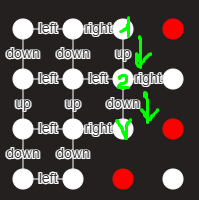

!!!!!!!!!!!!!!!!!!!!!

Our Agent uses BFS as a search algorithm 

With **BFS** we choose a node, n, with minimum value of some evaluation function, f(n).

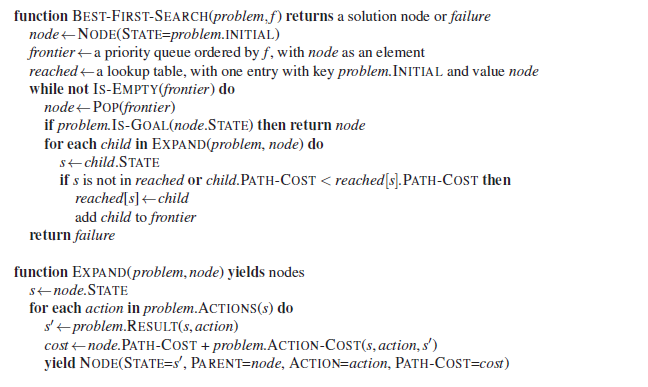

Let's create the environment for our Maze

In [ ]:
from src.navigationEnvironmentClass import MazeNavigationEnvironment

In [ ]:
maze_Env1=MazeNavigationEnvironment(mazeWorldGraph)

In [ ]:
maze_Env1.status.graph_dict

{(0, 0): {(0, 1): 1, (1, 0): 1},
 (0, 1): {(0, 0): 1, (0, 2): 1, (1, 1): 1},
 (0, 2): {(0, 1): 1, (1, 2): 1},
 (1, 0): {(0, 0): 1, (1, 1): 1, (2, 0): 1},
 (1, 1): {(1, 0): 1, (0, 1): 1, (1, 2): 1, (2, 1): 1},
 (1, 2): {(1, 1): 1, (0, 2): 1, (1, 3): 1, (2, 2): 1},
 (1, 3): {(1, 2): 1},
 (2, 0): {(1, 0): 1, (2, 1): 1, (3, 0): 1},
 (2, 1): {(2, 0): 1, (1, 1): 1, (2, 2): 1, (3, 1): 1},
 (2, 2): {(2, 1): 1, (1, 2): 1},
 (3, 0): {(2, 0): 1, (3, 1): 1},
 (3, 1): {(3, 0): 1, (2, 1): 1}}

In [ ]:
BFS_MazeAgent2=ProblemSolvingMazeAgentBFS(initState,mazeWorldGraph,goalState)

In [ ]:
BFS_MazeAgent2.performance

12

In [ ]:
print(initState,goalState)

(1, 1) (2, 2)


In [ ]:
nodeColors

{'wall': 'red', 'path': 'white'}

In [ ]:
nodeColors.setdefault('goal', "green")
nodeColors.setdefault('init', "gold")
nodeColors

{'wall': 'red', 'path': 'white', 'goal': 'green', 'init': 'gold'}

In [ ]:
for node in net_maze.nodes:
    if node['id']==intTupleTostr(goalState):
        node['color']=nodeColors['goal']
    elif node['id']==intTupleTostr(initState):
        node['color']=nodeColors['init']

In [ ]:
net_maze.show("graphMaze1.html", notebook=False)

graphMaze1.html


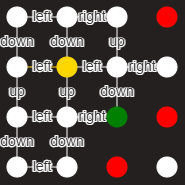

**!!!** As you can see the visualization of our Maze (above) is not complete enough (not all available actions are visible).
**You need to resolve this in your implementation.**

When we add the PS Agent into the Nav.Env. it should run its **__call__()** method (in the *SimpleProblemSolvingAgentProgram*)

The Agent must **Formulate a goal** and **Problem**, then **Search** for a sequence of actions that solves the problem.
    
The process (implemented in *__call__()*) has 4 main phases:
1. Goal Formulation (in the *MazeProblemSolvingAgent* class)
2. Problem Formulation (in the *MazeProblemSolvingAgent* class)
3. Search (in the *MazeProblemSolvingAgentSMART* class)
4. Execution of the resulting action sequence

In [ ]:
maze_Env1.add_thing(BFS_MazeAgent2)

<Node (1, 1)>
1
next_state (1, 0)
(1, 1) (1, 0)
1
1
next_state (0, 1)
(1, 1) (0, 1)
1
1
next_state (1, 2)
(1, 1) (1, 2)
1
1
next_state (2, 1)
(1, 1) (2, 1)
1
<Node (0, 1)>
1
next_state (0, 0)
(0, 1) (0, 0)
1
1
next_state (0, 2)
(0, 1) (0, 2)
1
1
next_state (1, 1)
(0, 1) (1, 1)
1
<Node (0, 0)>
1
next_state (0, 1)
(0, 0) (0, 1)
1
1
next_state (1, 0)
(0, 0) (1, 0)
1
<Node (0, 2)>
1
next_state (0, 1)
(0, 2) (0, 1)
1
1
next_state (1, 2)
(0, 2) (1, 2)
1
<Node (1, 0)>
1
next_state (0, 0)
(1, 0) (0, 0)
1
1
next_state (1, 1)
(1, 0) (1, 1)
1
1
next_state (2, 0)
(1, 0) (2, 0)
1
<Node (1, 2)>
1
next_state (1, 1)
(1, 2) (1, 1)
1
1
next_state (0, 2)
(1, 2) (0, 2)
1
1
next_state (1, 3)
(1, 2) (1, 3)
1
1
next_state (2, 2)
(1, 2) (2, 2)
1
<Node (1, 3)>
1
next_state (1, 2)
(1, 3) (1, 2)
1
<Node (2, 0)>
1
next_state (1, 0)
(2, 0) (1, 0)
1
1
next_state (2, 1)
(2, 0) (2, 1)
1
1
next_state (3, 0)
(2, 0) (3, 0)
1
<Node (2, 1)>
1
next_state (2, 0)
(2, 1) (2, 0)
1
1
next_state (1, 1)
(2, 1) (1, 1)
1
1
next_sta

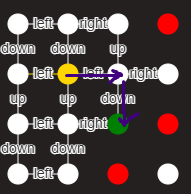

In [ ]:
maze_Env1.step()

Agent decided to do right.
Agent in right with performance = 11


In [ ]:
maze_Env1.step()

Agent decided to do down.
Agent in down with performance = 10
Agent reached all goals


In [ ]:
maze_Env1.step()

There is no one here who could work...


In [ ]:
testState=(0,1)

In [ ]:
goalState

(2, 2)

In [ ]:
BFSnavAgent3=ProblemSolvingMazeAgentBFS(testState,mazeWorldGraph,goalState)

In [ ]:
BFSnavAgent3.state

(0, 1)

In [ ]:
maze_Env1.add_thing(BFSnavAgent3)

<Node (0, 1)>
1
next_state (0, 0)
(0, 1) (0, 0)
1
1
next_state (0, 2)
(0, 1) (0, 2)
1
1
next_state (1, 1)
(0, 1) (1, 1)
1
<Node (0, 0)>
1
next_state (0, 1)
(0, 0) (0, 1)
1
1
next_state (1, 0)
(0, 0) (1, 0)
1
<Node (0, 2)>
1
next_state (0, 1)
(0, 2) (0, 1)
1
1
next_state (1, 2)
(0, 2) (1, 2)
1
<Node (1, 0)>
1
next_state (0, 0)
(1, 0) (0, 0)
1
1
next_state (1, 1)
(1, 0) (1, 1)
1
1
next_state (2, 0)
(1, 0) (2, 0)
1
<Node (1, 1)>
1
next_state (1, 0)
(1, 1) (1, 0)
1
1
next_state (0, 1)
(1, 1) (0, 1)
1
1
next_state (1, 2)
(1, 1) (1, 2)
1
1
next_state (2, 1)
(1, 1) (2, 1)
1
<Node (1, 2)>
1
next_state (1, 1)
(1, 2) (1, 1)
1
1
next_state (0, 2)
(1, 2) (0, 2)
1
1
next_state (1, 3)
(1, 2) (1, 3)
1
1
next_state (2, 2)
(1, 2) (2, 2)
1
<Node (1, 3)>
1
next_state (1, 2)
(1, 3) (1, 2)
1
<Node (2, 0)>
1
next_state (1, 0)
(2, 0) (1, 0)
1
1
next_state (2, 1)
(2, 0) (2, 1)
1
1
next_state (3, 0)
(2, 0) (3, 0)
1
<Node (2, 1)>
1
next_state (2, 0)
(2, 1) (2, 0)
1
1
next_state (1, 1)
(2, 1) (1, 1)
1
1
next_sta

In [ ]:
maze_Env1.run()

step 1:
Agent decided to do right.
Agent in right with performance = 11
step 2:
Agent decided to do down.
Agent in down with performance = 10
step 3:
Agent decided to do down.
Agent in down with performance = 9
Agent reached all goals


# Task-1: Rescue Robot in a Hazardous Laboratory Maze

In this assignment, a Rescue Robot (Agent) is trying to navigate a hazardous laboratory and find the shortest route from a starting cell to a rescue target.

The laboratory is represented as a maze containing blocked areas and security drones. The Rescue Robot must navigate through the laboratory while avoiding blocked cells and managing encounters with enemy drones.

1. **Model the Laboratory Maze Problem**

Model the laboratory as a graph where:

There is a node for the starting position.
There is a node for the rescue target.
There is a node for every location where the robot can make a meaningful choice between multiple paths.
Connect the nodes according to the available paths through the laboratory.

Generate a random \(7 \times 7\) laboratory maze as a NumPy matrix containing:

25% blocked cells representing walls/debris.
10% security drones representing enemies.
The remaining cells are available for the robot to visit.
One available cell must be designated as the rescue target.
One available cell must be designated as the starting position.

The generated maze should be visually or numerically distinguishable, for example:

* 0 = free cell
* 1 = wall/debris
* 2 = security drone
* 3 = rescue target
* 4 = robot starting position

2. **Define the Laboratory Environment, Rescue Robot Agent, and Security Drones**

The framework consists of a Laboratory Environment and a Rescue Robot Agent.

The environment is a square maze with four types of cells:

| Cell Type          | Description                                                                     |
| ------------------ | ------------------------------------------------------------------------------- |
| **Free cell**      | The robot can enter and move through this cell.                                 |
| **Wall/Debris**    | The robot cannot enter this cell.                                               |
| **Security Drone** | The robot can enter the cell, but an encounter may affect its remaining energy. |
| **Rescue Target**  | The robot's destination; reaching this cell completes the mission.              |


Each security **drone is a subclass of Thing** and has an **attack power**.

The drone's attack power is randomly generated in the range:

$$ 10\%-40\% \text{ of the number of nodes in the state-space graph} $$

The **Rescue Robot** has **a battery/energy level** that represents its remaining performance.

The robot can start from any valid free cell and is allowed to move only through cells that are not occupied by walls/debris.

The robot's mission: The sole purpose of the Rescue Robot is to reach the Rescue Target.

3. **Define the Robot's Actions**

The robot has exactly four movement actions, encoded as integers from 0–3:

| Action | Movement |
| -----: | -------- |
|  **0** | Left     |
|  **1** | Up       |
|  **2** | Right    |
|  **3** | Down     |


**Develop a transition model** according to the description above.


4. **Unknown Security Drones**

The *locations of the security drones are unknown to the Rescue Robot Agent*.

The robot therefore cannot simply use the complete maze information to avoid drones.

When the robot enters a cell containing a security drone, the drone becomes known to the agent.

**!!!** If the security drone has at least twice the attack power of the robot's current defensive capability, the drone captures the robot, and the agent dies.

Otherwise, the robot activates **Defense Mode**.

5. **Defense Mode**

When the Rescue Robot encounters a security drone and has sufficient defensive capability, it activates Defense Mode.

Activating Defense Mode:

* Allows the robot to survive the encounter.
* Allows the robot to continue moving through the drone's cell.
* Consumes 10% of the robot's current energy/performance.

For example, if the robot currently has:

$$ 100 \text{ energy units} $$

then activating Defense Mode reduces its energy to:

$$ 100 - 0.10(100)=90 $$

The updated energy level must become part of the agent's state.

# Task-2: Two Rescue Robot Agents in a Hazardous Laboratory Maze

Implement two Rescue Robot Agents, both starting from the same initial cell and operating in the same laboratory environment:

* Uniform-Cost Search (UCS) Agent
* Iterative Deepening / Iterative DLS Agent

Both agents must attempt to reach the same Rescue Target.

**Uniform-Cost Search Agent**

Implement the Rescue Robot agent using Best-First Search, where the evaluation function is the PATH-COST:

*f(n)=g(n)*

where \(g(n)\) is the total cost of the path from the initial state to node \(n\).

Use the following action costs:

| Action | Movement |  Cost |
| -----: | -------- | ----: |
|  **0** | Left     | **2** |
|  **1** | Up       | **4** |
|  **2** | Right    | **2** |
|  **3** | Down     | **1** |


**Iterative DLS Agent**

Implement the second Rescue Robot agent using Iterative Deepening Depth-First Search (IDDFS), based on the Iterative DLS algorithm.

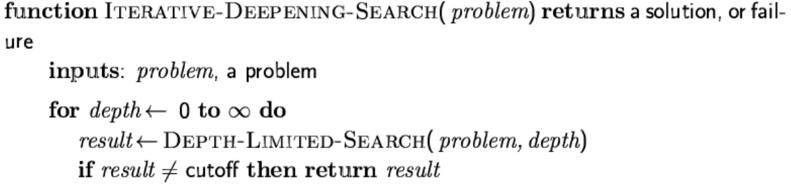

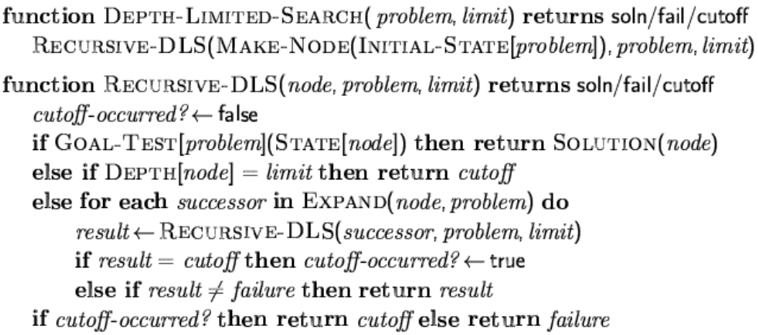

The agent should repeatedly perform Depth-Limited Search with increasing depth limits:
* Depth Limit = 0
* Depth Limit = 1
* Depth Limit = 2
* Depth Limit = 3
...

until:

* the Rescue Target is found, or
* the search determines that no solution exists.

**!!!** For each iteration, the DLS search starts again from the same initial state.

Add your implememtation as  `IDSearchAgentProgram` function (see the template in the `PS_agentPrograms.py`).

**Both agents:**

* Start at the same cell.
* Use the same laboratory maze.
* Have the same Rescue Target.
* Use the same four movement actions.
* Must obey the transition model.
* Must handle walls and laboratory boundaries.
* Must handle encounters with security drones.
* Must report whether they successfully reach the target.

Determine the winner - the agent that achieved the goal and maintained the highest performance.

Example of a Hazardous Laboratory Maze (with one Agent)

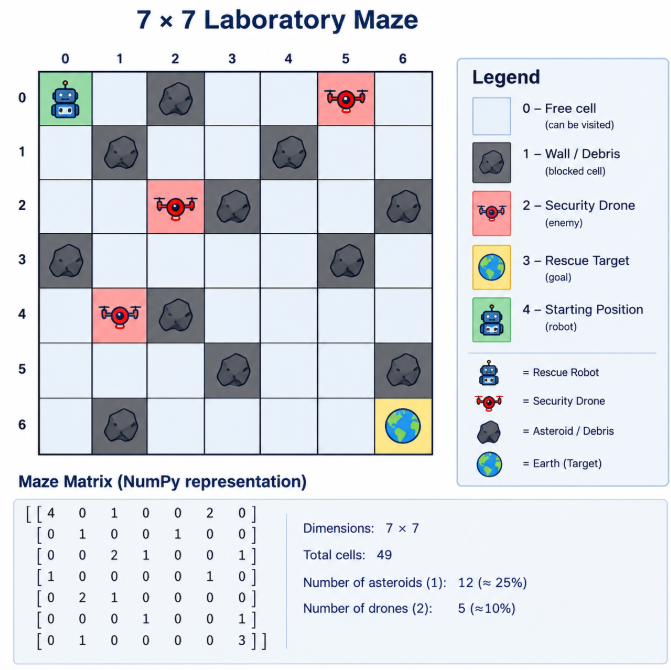

## Solution: Rescue Robots in the Hazardous Laboratory

New code (all in `src/`):

| File | What it does |
| --- | --- |
| `labMazeData.py` | the maze generator (7×7 NumPy matrix), the actions 0-3 and their costs, the transition model of the single moves |
| `labGraphClass.py` | `LabGraph(mazeGraph)` – the state-space graph: start, target, decision points and the corridors between them |
| `labMazeProblemClass.py` | `LabMazeProblem(Problem)` – the problem formulated on this graph |
| `securityDroneClass.py` | `SecurityDrone(Thing)` with a random attack power |
| `rescueRobotAgentClass.py` | `RescueRobotAgent` – the Problem-Solving Agent with `state = (position, energy)` |
| `labEnvironmentClass.py` | `LabEnvironment(environmentPro)` – moves, walls, boundaries, drones, Defense Mode, the winner |
| `PS_agentPrograms.py` | new: `UniformCostSearchAgentProgram` and `IDSearchAgentProgram` (+ `BestFirstSearch`, `DepthLimitedSearch`, `RecursiveDLS`) |
| `agents.py` | new: `RescueRobotAgentUCS`, `RescueRobotAgentIDS` |
| `labMazeVisual.py` | pictures of the laboratory (matplotlib) and the networks (pyvis) |
| `rescueMission.py` | a whole mission from one seed (used for the experiment and the web app) |
| `locations.py` | imported by `environmentProClass.py`, but missing in the starter code |

**Rules where the task leaves a choice:**
* **Energy.** The robot starts with a full battery: energy = performance = the number of nodes in the state-space graph (as in `MazeProblemSolvingAgentSMART`).
* **Moving costs energy.** Every move takes its action cost from the battery: Left 2, Up 4, Right 2, Down 1 – the costs from Task 2, the same for both robots. At energy 0 the battery is empty and the robot stops.
* **Defensive capability = the current energy.** A drone with attack power ≥ 2 × energy captures the robot; otherwise Defense Mode takes 10% of the current energy.

### Task 1.1 The laboratory maze

`makeLabMaze(n=7)` puts **round(25% × 49) = 12** walls/debris and **round(10% × 49) = 5** security drones on random cells, then the starting position and the rescue target on two of the remaining free cells:

**0** = free cell, **1** = wall/debris, **2** = security drone, **3** = rescue target, **4** = robot starting position

It makes new laboratories until the target can be reached from the start (`solvable=True`). The same `seed` gives the same laboratory (`SEED = None` – a new laboratory on every run).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from src.labMazeData import makeLabMaze, cellTypes, findCell, robotMap, START, TARGET
from src.labMazeVisual import plotLabMaze

SEED = 205  # None = a new random laboratory on every run

lab1 = makeLabMaze(7, seed=SEED)
lab1

array([[0, 0, 1, 1, 2, 2, 3],
       [4, 0, 0, 0, 0, 0, 2],
       [0, 0, 0, 0, 1, 0, 1],
       [1, 2, 0, 1, 1, 0, 2],
       [0, 1, 1, 0, 0, 0, 0],
       [1, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1]])

In [ ]:
{cellTypes[k]: int((lab1 == k).sum()) for k in cellTypes}

{'free cell': 30,
 'wall/debris': 12,
 'security drone': 5,
 'rescue target': 1,
 'starting position': 1}

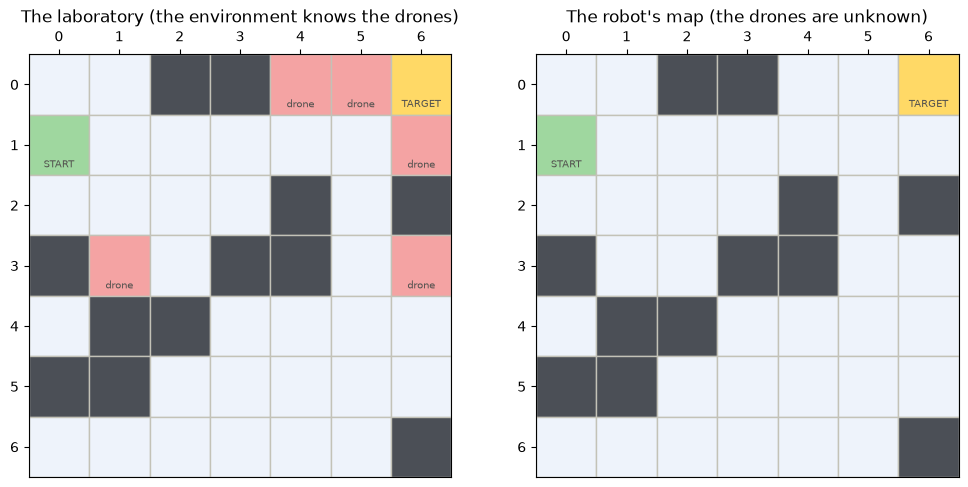

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plotLabMaze(lab1, 'The laboratory (the environment knows the drones)', ax=axes[0])
plotLabMaze(robotMap(lab1), "The robot's map (the drones are unknown)", ax=axes[1])
plt.show()

### Task 1.3 The robot's actions and the transition model

(The transition model is needed to build the graph, so it comes first.)

The robot has exactly four actions, the integers from `mazeData.py`: **0 = Left, 1 = Up, 2 = Right, 3 = Down**.

* `defineLabAvailableActions(maze)` – the available actions of every cell that is not a wall: a move is available if it stays inside the laboratory and doesn't go into a wall/debris. A drone doesn't block a cell – the robot can enter it.
* `makeLabTransitionModel(...)` – **RESULT(s, a)** of the single moves: `{cell: {action: next cell}}`.
* `labResult(TM, s, a)` – RESULT for any of the 4 actions: a wall/debris or the boundary blocks the move and the robot stays in its cell.

In [ ]:
from src.labMazeData import defineLabAvailableActions, makeLabTransitionModel, labResult, actionCosts
from src.mazeData import actions_dict

labActs = defineLabAvailableActions(lab1)
labTM = makeLabTransitionModel(labActs)
start1, target1 = findCell(lab1, START), findCell(lab1, TARGET)
print("start:", start1, " target:", target1)
labTM[start1]

start: (1, 0)  target: (0, 6)


{1: (0, 0), 2: (1, 1), 3: (2, 0)}

In [ ]:
# all 4 actions from the start: a wall/debris or the boundary blocks the move, the robot stays where it is
for action, name in actions_dict.items():
    print("{} {:5}  cost {}:  {} -> {}".format(action, name, actionCosts[action], start1, labResult(labTM, start1, action)))

0 left   cost 2:  (1, 0) -> (1, 0)
1 up     cost 4:  (1, 0) -> (0, 0)
2 right  cost 2:  (1, 0) -> (1, 1)
3 down   cost 1:  (1, 0) -> (2, 0)


#### A visualization with all available actions

In the tutorial's `net_maze` the edges were undirected, so pyvis kept only one edge for every pair of cells: the opposite action (e.g. *left* back from 0-1 to 0-0) was dropped and its label wasn't visible.

`cellNetwork` (in `labMazeVisual.py`) builds a **directed** network: every available action is its own **curved** arrow with its own label, so both directions between two cells are visible. Open `labMazeCells.html`.

In [ ]:
from src.labMazeVisual import cellNetwork, stateSpaceNetwork

netCells = cellNetwork(labTM, lab1, "labMazeCells.html")
print("available actions:", sum(len(acts) for acts in labTM.values()), "| arrows in the network:", len(netCells.edges))

available actions: 98 | arrows in the network: 98


### Task 1.1 The state-space graph

`LabGraph(labTM, start, target)` (derived from the tutorial's `mazeGraph`) has
* a node for the **starting position**,
* a node for the **rescue target**,
* a node for every **decision point** – a cell with 3 or 4 available actions, where the robot can make a meaningful choice between multiple paths.

The nodes are connected by the **corridors**: at a node the robot chooses a direction (0-3) and follows the corridor (cells with one way in and one way out) up to the next node.
* `origin = {node: {action: next node}}` – the transition model between the nodes,
* `corridors = {(node, action): [moves]}` – the single moves along the corridor (the robot executes these),
* `graph_dict = {node: {next node: cost}}` – the cost of a corridor = the sum of its action costs. Up is expensive and down is cheap, so A → B and B → A can cost different amounts.

A corridor that ends in a dead end is not an edge (it can never lead to the target), and neither is a corridor that loops back to its own node.

!!! Explore `src/labGraphClass.py`

In [ ]:
from src.labGraphClass import LabGraph

labGraph1 = LabGraph(labTM, start1, target1)
print("cells the robot can enter:", len(labTM))
print("nodes of the state-space graph:", len(labGraph1.nodes()))
print("decision points:", labGraph1.decisionPoints)
labGraph1.graph_dict

cells the robot can enter: 37
nodes of the state-space graph: 20
decision points: [(0, 5), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (2, 1), (2, 2), (3, 5), (4, 4), (4, 5), (4, 6), (5, 3), (5, 4), (5, 5), (6, 2), (6, 3), (6, 4)]


{(0, 5): {(1, 4): 3, (0, 6): 2, (1, 5): 1},
 (0, 6): {(0, 5): 2, (1, 5): 3},
 (1, 0): {(1, 1): 2, (2, 1): 3},
 (1, 1): {(1, 0): 2, (1, 2): 2, (2, 1): 1},
 (1, 2): {(1, 1): 2, (1, 3): 2, (2, 2): 1},
 (1, 3): {(1, 2): 2, (1, 4): 2, (2, 2): 3},
 (1, 4): {(1, 3): 2, (0, 5): 6, (1, 5): 2},
 (1, 5): {(1, 4): 2, (0, 5): 4, (0, 6): 6, (3, 5): 2},
 (2, 1): {(1, 0): 6, (1, 1): 4, (2, 2): 2},
 (2, 2): {(2, 1): 2, (1, 2): 4, (1, 3): 6},
 (3, 5): {(1, 5): 8, (4, 6): 3, (4, 5): 1},
 (4, 4): {(5, 3): 3, (4, 5): 2, (5, 4): 1},
 (4, 5): {(4, 4): 2, (3, 5): 4, (4, 6): 2, (5, 5): 1},
 (4, 6): {(4, 5): 2, (3, 5): 6, (5, 5): 3},
 (5, 3): {(6, 2): 3, (4, 4): 6, (5, 4): 2, (6, 3): 1},
 (5, 4): {(5, 3): 2, (4, 4): 4, (5, 5): 2, (6, 4): 1},
 (5, 5): {(5, 4): 2, (4, 5): 4, (4, 6): 6, (6, 4): 3},
 (6, 2): {(5, 3): 6, (6, 3): 2},
 (6, 3): {(6, 2): 2, (5, 3): 4, (6, 4): 2},
 (6, 4): {(6, 3): 2, (5, 4): 4, (5, 5): 6}}

In [ ]:
# the corridors from the start: the direction chosen at the node, the next node, the moves along the corridor and its cost
for action, nextNode in labGraph1.origin[start1].items():
    print("{} -> {}  moves {}  cost {}".format(actions_dict[action], nextNode, labGraph1.moves(start1, action), labGraph1.cost(start1, action)))

up -> (1, 1)  moves [1, 2, 3]  cost 7
right -> (1, 1)  moves [2]  cost 2
down -> (2, 1)  moves [3, 2]  cost 3


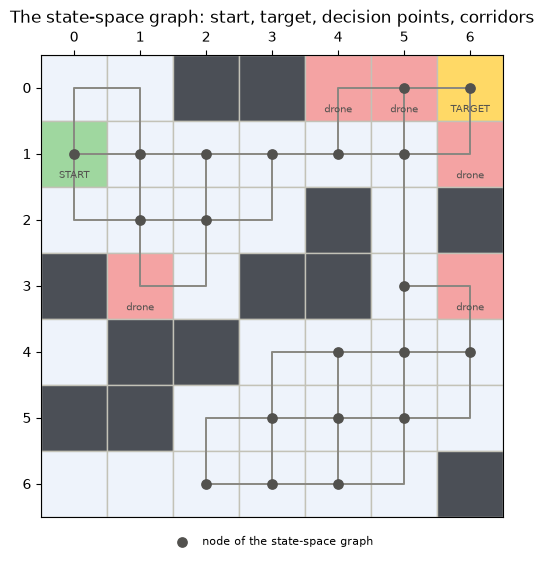

In [ ]:
plotLabMaze(lab1, 'The state-space graph: start, target, decision points, corridors', graph=labGraph1)
plt.show()
netGraph = stateSpaceNetwork(labGraph1, lab1, "labStateSpace.html")  # the interactive version: labStateSpace.html

#### The problem: `LabMazeProblem(Problem)`

* **Initial state** – the start node; **goal test** – the rescue target
* **ACTIONS(s)** – the directions (0-3) at the node s that lead into a corridor
* **RESULT(s, a)** – the node at the end of the corridor
* **ACTION-COST(s, a, s')** – the sum of the costs of the moves along the corridor

!!! Explore `src/labMazeProblemClass.py`

In [ ]:
from src.labMazeProblemClass import LabMazeProblem

lp1 = LabMazeProblem(start1, target1, labGraph1)
a = lp1.actions(start1)[0]
print("ACTIONS(start) =", lp1.actions(start1))
print("RESULT(start, {}) = {}".format(a, lp1.result(start1, a)))
print("path cost after this action =", lp1.path_cost(0, start1, a, lp1.result(start1, a)))
print("goal test: start", lp1.goal_test(start1), "| target", lp1.goal_test(target1))

ACTIONS(start) = [1, 2, 3]
RESULT(start, 1) = (1, 1)
path cost after this action = 7
goal test: start False | target True


### Task 1.2 The environment, the Rescue Robot and the security drones

* `LabEnvironment(environmentPro)`: `status` = the laboratory matrix, `things` = the security drones, `agents` = the robots.
* `SecurityDrone(Thing)`: its attack power is random, from 10% to 40% of the number of nodes in the state-space graph.
* `RescueRobotAgent(MazeProblemSolvingAgentSMART)`: `state = (position, energy)`. The energy starts at the number of nodes in the graph (a full battery) and it is the robot's performance. The robot knows the walls (the graph) but not the drones: `knownDrones` is empty at the start.

!!! Explore `src/labEnvironmentClass.py`, `src/securityDroneClass.py` and `src/rescueRobotAgentClass.py`

In [ ]:
from src.labEnvironmentClass import LabEnvironment

nodesCount = len(labGraph1.nodes())
labEnv1 = LabEnvironment(lab1, labTM, nodesCount, seed=SEED)  # the seed also fixes the attack powers
print("attack power range: {:.1f} - {:.1f}".format(0.1 * nodesCount, 0.4 * nodesCount))
labEnv1.things

attack power range: 2.0 - 8.0


[<SecurityDrone attack=4.6 in (0, 4)>,
 <SecurityDrone attack=6.3 in (0, 5)>,
 <SecurityDrone attack=5.2 in (1, 6)>,
 <SecurityDrone attack=5.0 in (3, 1)>,
 <SecurityDrone attack=7.0 in (3, 6)>]

### Task 1.4 Unknown security drones and 1.5 Defense Mode

`LabEnvironment.execute_action(robot, action)` makes one move:
1. the transition model moves the robot (a wall/debris or the boundary blocks it),
2. the move takes its action cost from the battery (energy ≤ 0 → the battery is empty, the robot stops),
3. a security drone in the new cell: the robot meets it and the drone becomes known (the percept carries the drone's attack power and `update_state` stores it in `knownDrones`):
   * attack power ≥ 2 × current energy → the drone **captures** the robot (the agent dies),
   * otherwise **Defense Mode**: the robot survives, can go on through the drone's cell and loses 10% of its current energy,
4. the robot perceives its new position and energy: the updated energy becomes part of its `state`.

A test: a robot next to a drone moves into the drone's cell – once with a full battery, once with a nearly empty one.

In [ ]:
from src.rescueRobotAgentClass import RescueRobotAgent
from src.PS_agentPrograms import UniformCostSearchAgentProgram

# a drone, a cell next to it and the action that moves the robot into the drone's cell
drone, neighbour, action = next((d, cell, a) for d in labEnv1.things for cell, acts in labTM.items()
                                for a, nextCell in acts.items() if nextCell == d.location)
print(drone, "| the robot starts in", neighbour, "and does", actions_dict[action], "\n")

for energy in (nodesCount, actionCosts[action] + 0.5):  # a full battery, a nearly empty battery
    testEnv = LabEnvironment(lab1, labTM, nodesCount, seed=SEED)
    tester = RescueRobotAgent(neighbour, labGraph1, target1, UniformCostSearchAgentProgram(), 'Test Robot', energy)
    tester.status = 'on the way'
    testEnv.agents.append(tester)  # only for this test: the robot gets no plan
    print("before:", tester.state, "known drones:", tester.knownDrones)
    testEnv.execute_action(tester, action)
    print("after: ", tester.state, "known drones:", tester.knownDrones, "status:", tester.status, "\n")

<SecurityDrone attack=4.6 in (0, 4)> | the robot starts in (0, 5) and does left 

before: ((0, 5), 20) known drones: {}
<Test Robot> in (0, 4) with energy = 18
<Test Robot> met a security drone with attack power 4.6 in (0, 4)
<Test Robot> activates Defense Mode: energy 18 -> 16.2
after:  ((0, 4), 16.2) known drones: {(0, 4): 4.6} status: on the way 

before: ((0, 5), 2.5) known drones: {}
<Test Robot> in (0, 4) with energy = 0.5
<Test Robot> met a security drone with attack power 4.6 in (0, 4)
The drone captured <Test Robot>: attack power 4.6 >= 2 x energy 0.5
after:  ((0, 4), 0.5) known drones: {(0, 4): 4.6} status: captured by a drone 



## Task 2. Two Rescue Robots: UCS vs IDDFS

Both robots are `RescueRobotAgent`s with the same start, laboratory, target, actions and transition model. Only the agent program – the search strategy – is different.

**UCS Robot** – `UniformCostSearchAgentProgram()`: `BestFirstSearch(problem, f)` (the BEST-FIRST-SEARCH pseudo-code above) with **f(n) = g(n) = PATH-COST**. The frontier is a priority queue ordered by the path cost, and the goal test is done when a node leaves the frontier, so the first solution found is the cheapest one. Costs: Left 2, Up 4, Right 2, Down 1.

**IDDFS Robot** – `IDSearchAgentProgram()` (ITERATIVE-DEEPENING-SEARCH): for depth = 0, 1, 2, … it runs `DepthLimitedSearch(problem, depth)` = `RecursiveDLS` from the pseudo-code, each time again from the initial state:
* goal test → solution; depth = limit → **cutoff**; otherwise expand the node and search the successors,
* `RecursiveDLS` returns **cutoff** if the limit cut some path, otherwise **failure**,
* IDS stops at the first solution, or when DLS returns **failure**: no path was cut, the whole graph was searched and there is no solution.
* The laboratory graph has cycles, so `RecursiveDLS` skips a successor whose state is already on the current path (`isCycle`, as in AIMA 4th ed.). Without it a path could go around a cycle forever: DLS would always return cutoff and IDS would never report failure.

IDDFS finds the solution with the fewest corridors (decisions); it doesn't look at the costs.

!!! Explore `src/PS_agentPrograms.py` and `src/agents.py`

In [ ]:
from src.agents import RescueRobotAgentUCS, RescueRobotAgentIDS

ucsRobot = RescueRobotAgentUCS(start1, labGraph1, target1)
idsRobot = RescueRobotAgentIDS(start1, labGraph1, target1)
labEnv1.add_thing(ucsRobot)  # the robot formulates its goal and the problem, then searches
labEnv1.add_thing(idsRobot)

<UCS Robot> starts in (1, 0) with energy 20
UCS: 15 nodes expanded, path cost = 16
<UCS Robot>: path through the nodes [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (0, 6)]
<UCS Robot>: solution (a sequence of actions) [2, 2, 2, 2, 2, 2, 1], path cost = 16
<IDDFS Robot> starts in (1, 0) with energy 20
IDS: depth limit = 0: cutoff (1 nodes visited)
IDS: depth limit = 1: cutoff (4 nodes visited)
IDS: depth limit = 2: cutoff (11 nodes visited)
IDS: depth limit = 3: cutoff (24 nodes visited)
IDS: depth limit = 4: cutoff (52 nodes visited)
IDS: depth limit = 5: cutoff (85 nodes visited)
IDS: depth limit = 6: solution (7 nodes visited)
<IDDFS Robot>: path through the nodes [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (0, 5), (0, 6)]
<IDDFS Robot>: solution (a sequence of actions) [1, 2, 3, 2, 2, 2, 1, 2, 2], path cost = 21


In [ ]:
labEnv1.run()

step 1:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 1 (up).
<UCS Robot> in (1, 1) with energy = 18
<IDDFS Robot> in (0, 0) with energy = 16
step 2:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 2 (right).
<UCS Robot> in (1, 2) with energy = 16
<IDDFS Robot> in (0, 1) with energy = 14
step 3:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 3 (down).
<UCS Robot> in (1, 3) with energy = 14
<IDDFS Robot> in (1, 1) with energy = 13
step 4:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 2 (right).
<UCS Robot> in (1, 4) with energy = 12
<IDDFS Robot> in (1, 2) with energy = 11
step 5:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 2 (right).
<UCS Robot> in (1, 5) with energy = 10
<IDDFS Robot> in (1, 3) with energy = 9
step 6:
<UCS Robot> decided to do 2 (right).
<IDDFS Robot> decided to do 2 (right).
<UCS Robot> in (1, 6) with energy = 8
<UCS Robot> met a security drone with attack power 5.2 in (1, 6

In [ ]:
pd.DataFrame(labEnv1.report())

,Agent,Reached target,Status,Energy (performance),Moves,Planned path cost,Drones met
0,UCS Robot,True,target reached,3.2,7,16,1
1,IDDFS Robot,False,captured by a drone,0.7,8,21,2


In [ ]:
winners = labEnv1.announce_winner()
for robot in labEnv1.agents:
    print(robot, "state =", robot.state, "| known drones:", robot.knownDrones)

The winner is <UCS Robot>: it reached the target with energy 3.2
<UCS Robot> state = ((0, 6), 3.2) | known drones: {(1, 6): 5.2}
<IDDFS Robot> state = ((0, 5), 0.7) | known drones: {(0, 4): 4.6, (0, 5): 6.3}


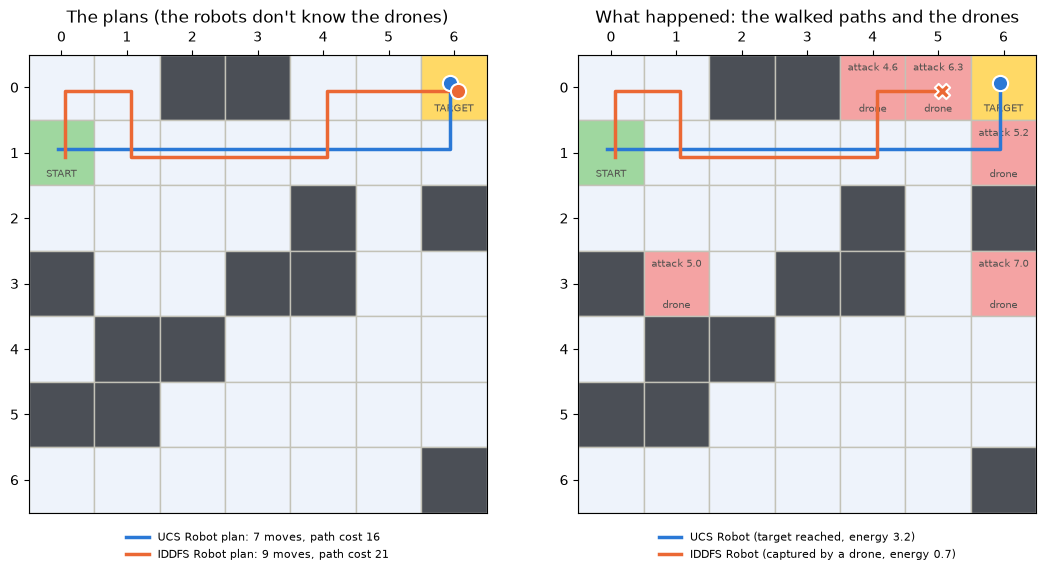

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
plotLabMaze(robotMap(lab1), "The plans (the robots don't know the drones)", agents=labEnv1.agents, planned=True, ax=axes[0])
plotLabMaze(lab1, 'What happened: the walked paths and the drones', agents=labEnv1.agents, drones=labEnv1.things, ax=axes[1])
plt.show()

#### Search details

In [ ]:
print("UCS:   path cost", ucsRobot.solution.path_cost, "| depth", ucsRobot.solution.depth, "| nodes expanded", ucsRobot.program.stats['expanded'])
print("IDDFS: path cost", idsRobot.solution.path_cost, "| depth", idsRobot.solution.depth,
      "| nodes visited in all iterations", sum(it[2] for it in idsRobot.program.iterations))
print("UCS nodes:  ", ucsRobot.nodePath())
print("IDDFS nodes:", idsRobot.nodePath())
pd.DataFrame(idsRobot.program.iterations, columns=['depth limit', 'DLS result', 'nodes visited'])

UCS:   path cost 16 | depth 6 | nodes expanded 15
IDDFS: path cost 21 | depth 6 | nodes visited in all iterations 184
UCS nodes:   [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (0, 6)]
IDDFS nodes: [(1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (0, 5), (0, 6)]


,depth limit,DLS result,nodes visited
0,0,cutoff,1
1,1,cutoff,4
2,2,cutoff,11
3,3,cutoff,24
4,4,cutoff,52
5,5,cutoff,85
6,6,solution,7


### A laboratory without a solution

With `solvable=False` the walls can cut the target off. Both robots must report that they can't reach it: UCS empties its frontier, IDDFS deepens the limit until DLS returns **failure** instead of cutoff.

(`makeLaboratory(seed)` from `rescueMission.py` does the steps above: maze → transition model → `LabGraph` → `LabEnvironment`.)

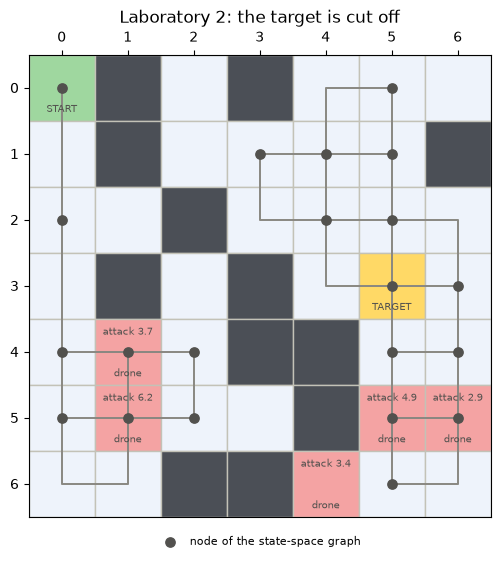

<UCS Robot> starts in (0, 0) with energy 21
UCS: 8 nodes expanded, no solution
<UCS Robot>: no solution - the rescue target (3, 5) can't be reached from (0, 0)
<IDDFS Robot> starts in (0, 0) with energy 21
IDS: depth limit = 0: cutoff (1 nodes visited)
IDS: depth limit = 1: cutoff (2 nodes visited)
IDS: depth limit = 2: cutoff (3 nodes visited)
IDS: depth limit = 3: cutoff (5 nodes visited)
IDS: depth limit = 4: cutoff (9 nodes visited)
IDS: depth limit = 5: cutoff (17 nodes visited)
IDS: depth limit = 6: cutoff (23 nodes visited)
IDS: depth limit = 7: cutoff (29 nodes visited)
IDS: depth limit = 8: failure (29 nodes visited)
<IDDFS Robot>: no solution - the rescue target (3, 5) can't be reached from (0, 0)


In [ ]:
from src.rescueMission import makeLaboratory

lab2, labGraph2, labEnv2 = makeLaboratory(seed=962, solvable=False)
plotLabMaze(lab2, 'Laboratory 2: the target is cut off', graph=labGraph2, drones=labEnv2.things)
plt.show()
labEnv2.add_thing(RescueRobotAgentUCS(labGraph2.start, labGraph2, labGraph2.target))
labEnv2.add_thing(RescueRobotAgentIDS(labGraph2.start, labGraph2, labGraph2.target))

In [ ]:
labEnv2.run()  # nothing to do: no robot has a plan
winners2 = labEnv2.announce_winner()
pd.DataFrame(labEnv2.report())

No winner: no robot reached the rescue target


,Agent,Reached target,Status,Energy (performance),Moves,Planned path cost,Drones met
0,UCS Robot,False,no solution,21,0,None,0
1,IDDFS Robot,False,no solution,21,0,None,0


### Who wins more often? 1000 random laboratories

`runRescueMission(seed)` builds the laboratory for the seed, adds both robots and runs the environment (the step-by-step log is kept in `env.log`).

In [ ]:
from src.rescueMission import runRescueMission

rows = []
for seed in range(1000):
    env = runRescueMission(seed)
    ucs, ids = env.agents
    winners = env.winner()
    rows.append({'seed': seed,
                 'UCS status': ucs.status, 'UCS energy': ucs.performance, 'UCS path cost': ucs.solution.path_cost,
                 'IDDFS status': ids.status, 'IDDFS energy': ids.performance, 'IDDFS path cost': ids.solution.path_cost,
                 'winner': 'tie' if len(winners) > 1 else (winners[0].name if winners else 'no winner')})
results = pd.DataFrame(rows)
results['winner'].value_counts()

winner
tie            616
no winner      182
UCS Robot      143
IDDFS Robot     59
Name: count, dtype: int64

In [ ]:
print("UCS plan cheaper than the IDDFS plan:", (results['UCS path cost'] < results['IDDFS path cost']).sum())
print("IDDFS plan cheaper than the UCS plan:", (results['UCS path cost'] > results['IDDFS path cost']).sum())
print("plans with the same cost:            ", (results['UCS path cost'] == results['IDDFS path cost']).sum())
pd.DataFrame({'UCS Robot': results['UCS status'].value_counts(), 'IDDFS Robot': results['IDDFS status'].value_counts()})

UCS plan cheaper than the IDDFS plan: 123
IDDFS plan cheaper than the UCS plan: 0
plans with the same cost:             877


,UCS Robot,IDDFS Robot
target reached,815,798
battery exhausted,167,181
captured by a drone,18,21


In [ ]:
# the laboratories where the IDDFS Robot won
results[results['winner'] == 'IDDFS Robot'].head()

,seed,UCS status,UCS energy,UCS path cost,IDDFS status,IDDFS energy,IDDFS path cost,winner
0,0,target reached,8.54,13,target reached,13.0,13,IDDFS Robot
34,34,captured by a drone,4.20,21,target reached,1.2,21,IDDFS Robot
44,44,target reached,15.80,5,target reached,18.0,5,IDDFS Robot
51,51,target reached,9.10,12,target reached,9.5,12,IDDFS Robot
74,74,target reached,2.57,20,target reached,4.1,20,IDDFS Robot


### Conclusions

* **Laboratory 1 (seed 205).** Both plans have the same depth – 6 corridors – but the UCS plan costs **16** and the IDDFS plan **21**. IDDFS tries the actions in the order 0, 1, 2, 3 and returns the first solution it finds at the shallowest depth, so it took the expensive *up* corridor at the start and, near the target, the *up* corridor through two drones. The IDDFS Robot spent more energy, met the second drone with energy 0.7 and was captured. The UCS Robot met one drone (Defense Mode) and reached the target with energy 3.2 → **the winner is the UCS Robot**.
* **UCS is optimal for the path cost.** In 1000 laboratories its plan was never more expensive than the IDDFS plan, and it was cheaper in 123 of them. **IDDFS is complete and finds the shallowest solution** (the fewest decisions), but it is optimal only when all actions cost the same – here they don't (Up 4, Down 1).
* **The drones are unknown**, so neither plan can avoid them. All 59 wins of the IDDFS Robot came from laboratories where both plans cost the same, but the UCS path met more (or stronger) drones. The UCS Robot won 143 times: 84 times thanks to a cheaper plan and 59 times thanks to fewer drones.
* In 616 laboratories both robots reached the target with the same energy (a tie; usually they planned the same path). In 182 laboratories no robot reached the target: with a battery of "number of nodes" energy units some targets are too far away (battery exhausted), or a drone captured a weakened robot.

### Web App

```
streamlit run lab4app_rescueRobots.py
```